# Importação das bibliotecas

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Leitura de dados

In [ ]:
df = pd.read_csv('dataset semcomp - Página1.csv')
display(df.head())

print(f"Formato do dataset: {df.shape}")
print("\nInformações das colunas:")
df.info()


,idade_pessoa,genero_pessoa,escolaridade_pessoa,renda_pessoa,tempo_emprego_pessoa,posse_imovel_pessoa,valor_emprestimo,motivo_emprestimo,taxa_juros_emprestimo,percentual_renda_emprestimo,tempo_historico_credito,pontuacao_credito,historico_inadimplencia,status_emprestimo
0,22.0,feminino,Mestrado,71948.0,0,ALUGUEL,35000.0,PESSOAL,16.02,0.49,3.0,561,Não,1
1,21.0,feminino,Ensino Médio,12282.0,0,PRÓPRIO,1000.0,EDUCAÇÃO,11.14,0.08,2.0,504,Sim,0
2,25.0,feminino,Ensino Médio,12438.0,3,FINANCIADO,5500.0,MÉDICO,12.87,0.44,3.0,635,Não,1
3,23.0,feminino,Bacharelado,79753.0,0,ALUGUEL,35000.0,MÉDICO,15.23,0.44,2.0,675,Não,1
4,24.0,masculino,Mestrado,66135.0,1,ALUGUEL,35000.0,MÉDICO,14.27,0.53,4.0,586,Não,1


Formato do dataset: (45000, 14)

Informações das colunas:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   idade_pessoa                 45000 non-null  float64
 1   genero_pessoa                45000 non-null  object 
 2   escolaridade_pessoa          45000 non-null  object 
 3   renda_pessoa                 45000 non-null  float64
 4   tempo_emprego_pessoa         45000 non-null  int64  
 5   posse_imovel_pessoa          45000 non-null  object 
 6   valor_emprestimo             45000 non-null  float64
 7   motivo_emprestimo            45000 non-null  object 
 8   taxa_juros_emprestimo        45000 non-null  float64
 9   percentual_renda_emprestimo  45000 non-null  float64
 10  tempo_historico_credito      45000 non-null  float64
 11  pontuacao_credito            45000 non-null  int64  
 12  historico_inadim

# Pré-processamento
Nessa etapa precisamos limpar os dados "sujos" presentes no nosso dataset e que possam interferir no treinamento do modelo, dados nulos, NaN ou fora do padrão são removidos

In [ ]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

colunas_categoricas = ['genero_pessoa', 'escolaridade_pessoa', 'posse_imovel_pessoa',
                       'motivo_emprestimo', 'historico_inadimplencia']
colunas_numericas = ['idade_pessoa', 'renda_pessoa', 'tempo_emprego_pessoa',
                     'valor_emprestimo', 'taxa_juros_emprestimo',
                     'percentual_renda_emprestimo', 'tempo_historico_credito',
                     'pontuacao_credito']

# Verificação de nulos e duplicatas
print("Valores nulos por coluna:")
print(df.isnull().sum())
print(f"\nLinhas duplicadas: {df.duplicated().sum()}")

# Separa X e y
X = df.drop('status_emprestimo', axis=1)
y = df['status_emprestimo']

# Separação dos dados de treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Definição do pré-processador dos dados utilizando One-hot Encoder (Supervisionado)
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), colunas_categoricas),
        ('num', StandardScaler(), colunas_numericas)
    ]
)

# Dados são inseridos no modelo
preprocessor.fit(X_train)
X_train_transformado = preprocessor.transform(X_train)
X_test_transformado  = preprocessor.transform(X_test)

colunas_transformadas = preprocessor.get_feature_names_out()

print("--- ANTES (Dados Brutos) ---")
display(X_train.head(3))

print("\n--- DEPOIS (Dados Transformados) ---")
display(pd.DataFrame(X_train_transformado[:3], columns=colunas_transformadas))

print(f"\nShape X_train: {X_train.shape} -> {X_train_transformado.shape}")
print(f"Shape X_test:  {X_test.shape}  -> {X_test_transformado.shape}")

Valores nulos por coluna:
idade_pessoa                   0
genero_pessoa                  0
escolaridade_pessoa            0
renda_pessoa                   0
tempo_emprego_pessoa           0
posse_imovel_pessoa            0
valor_emprestimo               0
motivo_emprestimo              0
taxa_juros_emprestimo          0
percentual_renda_emprestimo    0
tempo_historico_credito        0
pontuacao_credito              0
historico_inadimplencia        0
status_emprestimo              0
dtype: int64

Linhas duplicadas: 0
--- ANTES (Dados Brutos) ---


,idade_pessoa,genero_pessoa,escolaridade_pessoa,renda_pessoa,tempo_emprego_pessoa,posse_imovel_pessoa,valor_emprestimo,motivo_emprestimo,taxa_juros_emprestimo,percentual_renda_emprestimo,tempo_historico_credito,pontuacao_credito,historico_inadimplencia
6048,24.0,masculino,Mestrado,58914.0,2,PRÓPRIO,4400.0,EMPREENDIMENTO,5.99,0.07,4.0,656,Sim
3346,23.0,feminino,Ensino Médio,45873.0,2,ALUGUEL,11000.0,EMPREENDIMENTO,11.01,0.24,2.0,634,Sim
17998,29.0,feminino,Mestrado,240947.0,7,FINANCIADO,10000.0,EMPREENDIMENTO,12.69,0.04,9.0,638,Sim



--- DEPOIS (Dados Transformados) ---


,cat__genero_pessoa_feminino,cat__genero_pessoa_masculino,cat__escolaridade_pessoa_Bacharelado,cat__escolaridade_pessoa_Doutorado,cat__escolaridade_pessoa_Ensino Médio,cat__escolaridade_pessoa_Mestrado,cat__escolaridade_pessoa_Tecnólogo,cat__posse_imovel_pessoa_ALUGUEL,cat__posse_imovel_pessoa_FINANCIADO,cat__posse_imovel_pessoa_OUTRO,...,cat__historico_inadimplencia_Não,cat__historico_inadimplencia_Sim,num__idade_pessoa,num__renda_pessoa,num__tempo_emprego_pessoa,num__valor_emprestimo,num__taxa_juros_emprestimo,num__percentual_renda_emprestimo,num__tempo_historico_credito,num__pontuacao_credito
0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,-0.622502,-0.256600,-0.561597,-0.823150,-1.687749,-0.800883,-0.480436,0.464300
1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,-0.787921,-0.411269,-0.561597,0.224243,-0.001061,1.154322,-0.996078,0.026852
2,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.204591,1.902342,0.262920,0.065547,0.563408,-1.145920,0.808671,0.106388



Shape X_train: (36000, 13) -> (36000, 27)
Shape X_test:  (9000, 13)  -> (9000, 27)


# Padronização e normalização dos dados
Após limpos, os dados são limitados a um intervalo de [-1,1] e [0,1] utilizando o Z-Score e o Min-Max

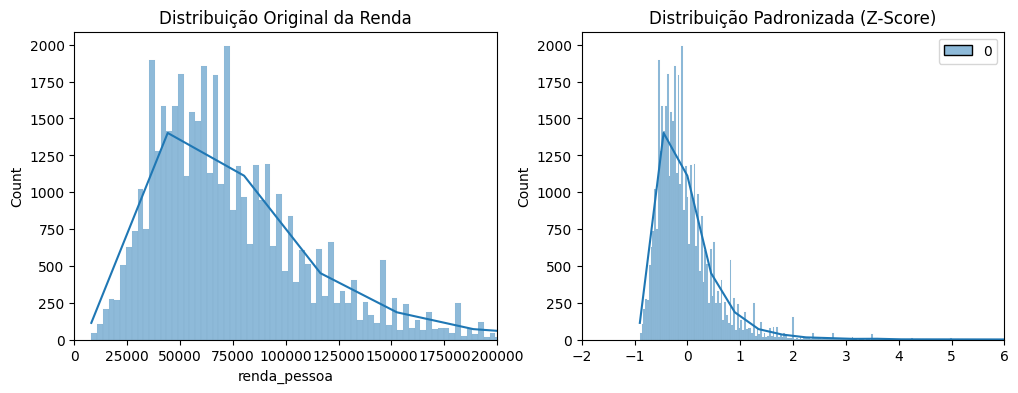

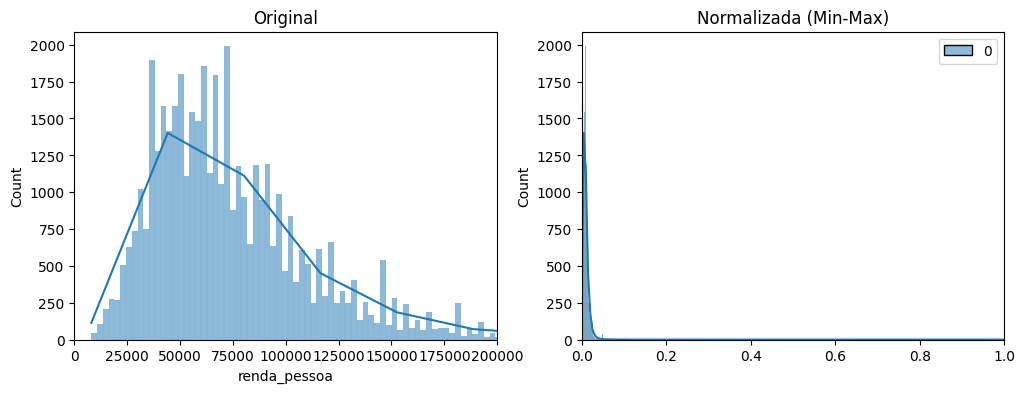

In [ ]:
#padronização e normalização
from sklearn.preprocessing import MinMaxScaler

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['renda_pessoa'], kde=True)
plt.title('Distribuição Original da Renda')
plt.xlim(0, 200000)

plt.subplot(1, 2, 2)
renda_padronizada = StandardScaler().fit_transform(df[['renda_pessoa']])
sns.histplot(renda_padronizada, kde=True)
plt.title('Distribuição Padronizada (Z-Score)')
plt.xlim(-2, 6)
plt.show()

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['renda_pessoa'], kde=True)
plt.title('Original')
plt.xlim(0, 200000)

plt.subplot(1, 2, 2)
renda_normalizada = MinMaxScaler().fit_transform(df[['renda_pessoa']])
sns.histplot(renda_normalizada, kde=True)
plt.title('Normalizada (Min-Max)')
plt.xlim(0, 1)
plt.show()

# Treinamento Supervisionado

Relatório - KNN:
              precision    recall  f1-score   support

           0       0.92      0.95      0.93      7000
           1       0.79      0.72      0.75      2000

    accuracy                           0.90      9000
   macro avg       0.86      0.83      0.84      9000
weighted avg       0.89      0.90      0.89      9000

Relatório - Naive Bayes:
              precision    recall  f1-score   support

           0       1.00      0.66      0.80      7000
           1       0.46      1.00      0.63      2000

    accuracy                           0.74      9000
   macro avg       0.73      0.83      0.71      9000
weighted avg       0.88      0.74      0.76      9000

Relatório - Árvore de Decisão:
              precision    recall  f1-score   support

           0       0.94      0.93      0.93      7000
           1       0.77      0.77      0.77      2000

    accuracy                           0.90      9000
   macro avg       0.85      0.85      0.85      9000
w

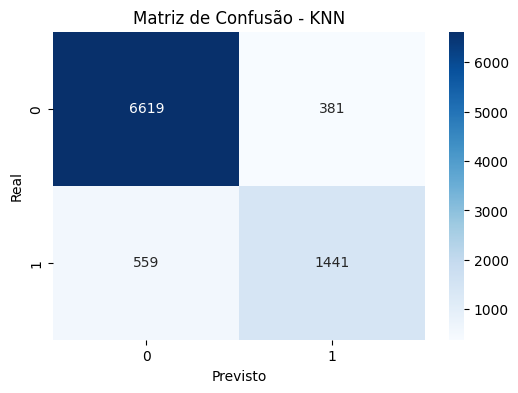

Comparação de Acurácia (mesmo X_test):
  KNN: 0.896
  Naive Bayes: 0.736
  Árvore de Decisão: 0.898
  Floresta Aleatória: 0.928


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Função para auxiliar a criação do pipeline de treinamento para o uso do One-Hot Encoder no treinamento proposto
def criar_pipeline(classificador):
    return Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', classificador)
    ])

pipeline_knn = criar_pipeline(KNeighborsClassifier(n_neighbors=5))
pipeline_nb  = criar_pipeline(GaussianNB())
pipeline_dt  = criar_pipeline(DecisionTreeClassifier(random_state=42))
pipeline_rf  = criar_pipeline(RandomForestClassifier(random_state=42))

# ---- Treina e avalia cada modelo ----
pipeline_knn.fit(X_train, y_train); y_pred    = pipeline_knn.predict(X_test)
pipeline_nb.fit(X_train, y_train);  y_pred_nb = pipeline_nb.predict(X_test)
pipeline_dt.fit(X_train, y_train);  y_pred_dt = pipeline_dt.predict(X_test)
pipeline_rf.fit(X_train, y_train);  y_pred_rf = pipeline_rf.predict(X_test)

# ---- Relatórios ----
print("Relatório - KNN:")
print(classification_report(y_test, y_pred))

print("Relatório - Naive Bayes:")
print(classification_report(y_test, y_pred_nb))

print("Relatório - Árvore de Decisão:")
print(classification_report(y_test, y_pred_dt))

print("Relatório - Floresta Aleatória:")
print(classification_report(y_test, y_pred_rf))

# ---- Matriz de Confusão KNN ----
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusão - KNN')
plt.xlabel('Previsto'); plt.ylabel('Real')
plt.show()

# ---- Comparação de Acurácia ----
modelos_pred = {
    'KNN': y_pred,
    'Naive Bayes': y_pred_nb,
    'Árvore de Decisão': y_pred_dt,
    'Floresta Aleatória': y_pred_rf,
}
print("Comparação de Acurácia (mesmo X_test):")
for nome, pred in modelos_pred.items():
    print(f"  {nome}: {accuracy_score(y_test, pred):.3f}")


In [ ]:
# =========================================================
# BLOCO 4 — EXERCÍCIO: Ajuste de hiperparâmetros
# =========================================================
# for k in [3, 5, 7, 11, 15]:
#     pipe = criar_pipeline(KNeighborsClassifier(n_neighbors=k))
#     pipe.fit(X_train, y_train)
#     acc = accuracy_score(y_test, pipe.predict(X_test))
#     print(f"K={k}: Acurácia = {acc:.3f}")

# Treinamento não supervisionado

K-Means aplicado!
Centroides:
[[-3.28937586e-01 -6.80219925e-02 -3.25730447e-01 -5.19859672e-01
  -1.87367840e-01 -4.91444045e-01 -3.20308139e-01 -7.18919820e-02]
 [-2.42708857e-01  1.33501127e-03 -2.45295415e-01  1.04463146e+00
   3.65288835e-01  1.06601282e+00 -2.34535172e-01 -4.10877371e-02]
 [ 1.89171014e+00  2.83654034e-01  1.88360327e+00  8.88648592e-03
   2.66143286e-02 -1.55396418e-01  1.83831235e+00  3.88490659e-01]]


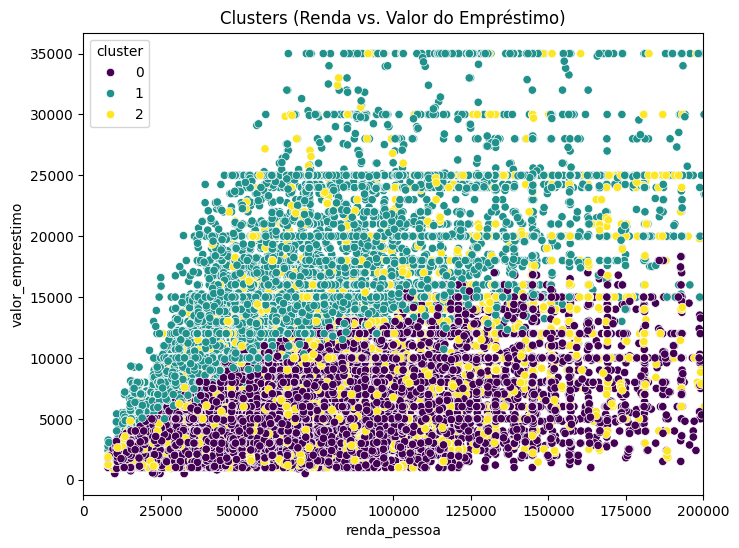

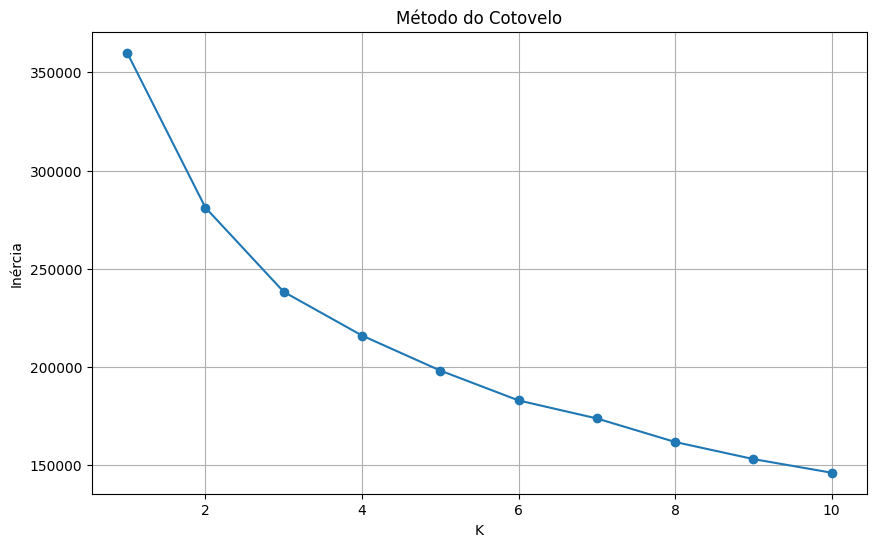

In [ ]:
from sklearn.cluster import KMeans

df_original = df.copy()

X_cluster = df[colunas_numericas]
X_cluster_scaled = StandardScaler().fit_transform(X_cluster)

# K-Means
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X_cluster_scaled)
df['cluster'] = kmeans.labels_

print("K-Means aplicado!")
print(f"Centroides:\n{kmeans.cluster_centers_}")

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='renda_pessoa', y='valor_emprestimo',
                hue='cluster', palette='viridis')
plt.title('Clusters (Renda vs. Valor do Empréstimo)')
plt.xlim(0, 200000)
plt.show()

# ---- Método do Cotovelo ----
inercia = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cluster_scaled)
    inercia.append(km.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), inercia, marker='o')
plt.title('Método do Cotovelo')
plt.xlabel('K'); plt.ylabel('Inércia')
plt.grid(True); plt.show()

In [ ]:
#EXERCÍCIO: Interpretação dos clusters
# analise = df.groupby('cluster')[colunas_numericas].mean()
# display(analise)

In [ ]:
#validação

# 7.1 Hold-Out já foi feito no Bloco 2.
# Se quiser um conjunto de VALIDAÇÃO, separe a partir do TREINO (nunca do teste):
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)
print(f"Treino final: {X_train_final.shape}")
print(f"Validação:    {X_val.shape}")
print(f"Teste:        {X_test.shape}  # intocado")

# 7.2 Validação Cruzada — usa X_train (NÃO o X completo!)
from sklearn.model_selection import cross_val_score

scores = cross_val_score(pipeline_knn, X_train, y_train, cv=5, scoring='accuracy')
print(f"Scores por fold: {scores}")
print(f"Média: {scores.mean():.3f}")
print(f"Desvio padrão: {scores.std():.3f}")

Treino final: (28800, 13)
Validação:    (7200, 13)
Teste:        (9000, 13)  # intocado
Scores por fold: [0.89902778 0.89277778 0.88652778 0.89611111 0.88944444]
Média: 0.893
Desvio padrão: 0.004


In [ ]:
#EXERCÍCIO: CV em múltiplos modelos


modelos_cv = {
    'KNN': pipeline_knn,
    'Naive Bayes': pipeline_nb,
    'Árvore de Decisão': pipeline_dt,
    'Floresta Aleatória': pipeline_rf,
}

resultados = {}
for nome, pipe in modelos_cv.items():
    s = cross_val_score(pipe, X_train, y_train, cv=5, scoring='accuracy')
    resultados[nome] = (s.mean(), s.std())
    print(f"{nome}: média={s.mean():.3f}, desvio={s.std():.3f}")

melhor = max(resultados, key=lambda k: resultados[k][0])
mais_estavel = min(resultados, key=lambda k: resultados[k][1])
print(f"\n Melhor média: {melhor}")
print(f" Mais estável: {mais_estavel}")

KNN: média=0.893, desvio=0.004
Naive Bayes: média=0.731, desvio=0.004
Árvore de Decisão: média=0.900, desvio=0.001
Floresta Aleatória: média=0.928, desvio=0.002

🏆 Melhor média: Floresta Aleatória
🎯 Mais estável: Árvore de Decisão
